<a href="https://colab.research.google.com/github/irdinafishar-bit/Predicting-Agricultural-Crop-Production-by-Yield-using-Machine-Learning/blob/main/Predicting_Agricultural_Crop_Production_by_Yield_using_Machine_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



---

**Data Preprocessing**


---



In [ ]:
# STEP 1: Importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Mount Google Drive and load datasets
from google.colab import drive
drive.mount('/content/drive')

# Load crop production and planted area data CSV files from Google Drive
prod_df = pd.read_csv('/content/drive/MyDrive/crops_district_production.csv')
area_df = pd.read_csv('/content/drive/MyDrive/crops_district_area.csv')


Mounted at /content/drive


In [ ]:
# STEP 2: Cleaning columns
# Clean categorical text columns by stripping whitespace, replacing underscores with spaces, and title-casing for consistency
columns_to_clean = ['state', 'district', 'crop_type', 'crop_species']

for col in columns_to_clean:
    if col in prod_df.columns:
        prod_df[col] = prod_df[col].str.strip().str.replace('_', ' ', regex=False).str.title()
    if col in area_df.columns:
        area_df[col] = area_df[col].str.strip().str.replace('_', ' ', regex=False).str.title()

# Drop columns not needed for analysis to reduce dataset size
prod_df.drop(columns=['state', 'crop_type', 'date'], inplace=True)
area_df.drop(columns=['state', 'crop_type', 'date'], inplace=True)

# Add a 'year' column with value 2017 since data corresponds to that year
prod_df['year'] = 2017
area_df['year'] = 2017

print("🔍 Rows in production data:", len(prod_df))
print("🔍 Rows in area data:", len(area_df))
merged_df = pd.merge(prod_df, area_df, on=['district', 'crop_species', 'year'], how='inner')

# Merge production and area data on common keys: district, crop_species, year
print("✅ Rows after merge (inner join):",len(merged_df))

🔍 Rows in production data: 11002
🔍 Rows in area data: 10555
✅ Rows after merge (inner join): 11037


In [ ]:
# STEP 3: Cleaning data
# Data validation - identify any rows with negative values (invalid)
invalid_rows = merged_df[(merged_df['production'] < 0) | (merged_df['planted_area'] < 0)]
print(f"\nRows with negative production or planted area: {len(invalid_rows)}")
if not invalid_rows.empty:
    print(invalid_rows)

# Data validation - Remove invalid rows with negative production or planted area
merged_df = merged_df[(merged_df['production'] >= 0) & (merged_df['planted_area'] >= 0)]

# Confirming no invalid rows remain
remaining_invalid = merged_df[(merged_df['production'] < 0) | (merged_df['planted_area'] < 0)]
print(f"Number of invalid rows after filtering: {len(remaining_invalid)}")

# Check for exact duplicate rows in the dataset
exact_dupes = merged_df[merged_df.duplicated(keep=False)]
print(f"\n🔁 Exact duplicate rows: {len(exact_dupes)}")
if not exact_dupes.empty:
    print(exact_dupes.head())

# Drop exact duplicate rows to avoid redundancy
merged_df = merged_df.drop_duplicates()

# 📏 Show number of rows after dropping
print(f"📏 Shape after dropping exact duplicates: {merged_df.shape}")

# Identify rows with duplicate keys (district, crop_species, year) before aggregation
dup_rows = merged_df[merged_df.duplicated(subset=['district', 'crop_species', 'year'], keep=False)]
print(f"\nRows with duplicate keys: {len(dup_rows)}")
if not dup_rows.empty:
    print(dup_rows.head())

# Aggregate duplicates by summing production and planted area
merged_df = merged_df.groupby(['district', 'crop_species', 'year'], as_index=False).agg({
    'production': 'sum',
    'planted_area': 'sum'
})

# Verify duplicates are removed after aggregation
post_agg_dupes = merged_df.duplicated(subset=['district', 'crop_species', 'year']).sum()
print(f"\n🔁 Duplicates after aggregation: {post_agg_dupes}")
print(f"\n📏 Shape after aggregation: {merged_df.shape}")

# Filter out bad rows
merged_df = merged_df[~((merged_df['production'] == 0) & (merged_df['planted_area'] == 0))]

# Show number of rows after filtering out bad rows
print(f"📏 Shape after filtering out (0 production & 0 area): {merged_df.shape}")

# Count unique districts and crop species
num_districts = merged_df['district'].nunique()
num_crop_species = merged_df['crop_species'].nunique()

print(f"📍 Number of unique districts: {num_districts}")
print(f"🌾 Number of unique crop species: {num_crop_species}")



Rows with negative production or planted area: 0
Number of invalid rows after filtering: 0

🔁 Exact duplicate rows: 494
    district crop_species  production  year  planted_area
837  Tangkak    Areca Nut         0.0  2017           0.0
838  Tangkak    Areca Nut         0.0  2017           0.0
839  Tangkak    Areca Nut         0.0  2017           0.0
840  Tangkak    Areca Nut         0.0  2017           0.0
845  Tangkak       Coffee         0.0  2017           0.0
📏 Shape after dropping exact duplicates: (10679, 5)

Rows with duplicate keys: 820
    district crop_species  production  year  planted_area
841  Tangkak      Coconut     12384.5  2017        2551.2
842  Tangkak      Coconut     12384.5  2017           0.0
843  Tangkak      Coconut         0.0  2017        2551.2
844  Tangkak      Coconut         0.0  2017           0.0
857  Tangkak     Mushroom      2135.8  2017          62.6

🔁 Duplicates after aggregation: 0

📏 Shape after aggregation: (10072, 5)
📏 Shape after filtering ou

In [ ]:
# Importing libraries
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# STEP 4: Feature engineering
# Calculate yield as production divided by planted area (avoid division by zero)
merged_df['yield'] = merged_df['production'] / (merged_df['planted_area'] + 1e-6)

# Log-transform yield and planted area for better distribution and modeling
merged_df['log_yield'] = np.log1p(merged_df['yield'])
merged_df['log_area'] = np.log1p(merged_df['planted_area'])

# Additional features:
# Production per area (similar to yield) for modeling
merged_df['prod_per_area'] = merged_df['production'] / (merged_df['planted_area'] + 1e-6)

# Mean yield per district to capture district-level productivity trends
merged_df['mean_district_yield'] = merged_df.groupby('district')['yield'].transform('mean')

In [ ]:
# Step 5: Simplify categories by limiting to top 135 districts and top 100 species
TOP_N_DISTRICTS = 135
TOP_N_SPECIES = 114
top_districts = merged_df['district'].value_counts().nlargest(TOP_N_DISTRICTS).index
top_species = merged_df['crop_species'].value_counts().nlargest(TOP_N_SPECIES).index

merged_df['district'] = merged_df['district'].where(merged_df['district'].isin(top_districts), 'Other')
merged_df['crop_species'] = merged_df['crop_species'].where(merged_df['crop_species'].isin(top_species), 'Other')

# STEP 6: Convert categorical variables into one-hot encoded columns for modeling
df_encoded = pd.get_dummies(merged_df, columns=['district', 'crop_species'], drop_first=True)

# STEP 7: Prepare features and target for modeling
y = df_encoded['log_yield']                   # Target variable (log-transformed yield)
planted_area_values = df_encoded['planted_area']  # Needed to transform predictions back to original scale
X = df_encoded.drop(columns=['production', 'yield', 'log_yield', 'planted_area'])

# Split data into training and test sets (80% train, 20% test)
X_train, X_test, y_train, y_test, pa_train, pa_test = train_test_split(
    X, y, planted_area_values, test_size=0.2, random_state=42)

all_results = {}  # Store outputs from all models for unified comparison



---
**Supervised Learning Models**


---



Model 1 - Random Forest Regressor 🌳

In [ ]:
# Import library
from sklearn.ensemble import RandomForestRegressor
# Initialize and train the Random Forest model

# ------------------ ⚙️ Pre-Tuning Evaluation ------------------ #
# Train baseline Random Forest with default hyperparameters
baseline_rf = RandomForestRegressor(random_state=42)
baseline_rf.fit(X_train, y_train)

# Predict and evaluate
baseline_pred_yield = np.expm1(baseline_rf.predict(X_test))
baseline_pred_production = baseline_pred_yield * pa_test.values
baseline_true_production = np.expm1(y_test) * pa_test.values

# Evaluation metrics for baseline
baseline_mae = mean_absolute_error(baseline_true_production, baseline_pred_production)
baseline_rmse = np.sqrt(mean_squared_error(baseline_true_production, baseline_pred_production))
baseline_r2 = r2_score(baseline_true_production, baseline_pred_production)

# Print baseline evaluation
print("\n🧪 Baseline Random Forest Evaluation (before tuning):")
print(f"R² Score        : {baseline_r2:.3f}")
print(f"MAE (tonnes)    : {baseline_mae:.2f}")
print(f"RMSE (tonnes)   : {baseline_rmse:.2f}")

# Hyperparameter tuning for Random Forest using randomized search
rf_params = {
    'n_estimators': [100, 150, 200, 250, 300],          # More trees for stability
    'max_depth': [10, 20, 30, None],                   # More depths to allow complexity or no limit
    'min_samples_leaf': [1, 2, 4, 8],                  # Larger leaf sizes to reduce overfitting & handle outliers better
    'min_samples_split': [2, 5, 10],                   # Added min_samples_split to control split quality
    'max_features': ['sqrt', 0.3, 0.5, 0.7, None],     # More options for features considered at each split
    'bootstrap': [True, False]                          # Option to toggle bootstrap sampling
}

# Tune Random Forest using RandomizedSearchCV
rf_random = RandomizedSearchCV(
    estimator=RandomForestRegressor(random_state=42),  # Base model
    param_distributions=rf_params,                     # Hyperparameter space
    n_iter=50,                                          # Number of random combinations to try
    cv=3,                                               # 3-fold cross-validation
    scoring='neg_root_mean_squared_error',             # Evaluation metric
    n_jobs=-1,                                          # Use all available CPUs
    verbose=1,                                          # Print progress
    random_state=42                                    # For reproducibility
)

# Train the model with hyperparameter tuning
rf_random.fit(X_train, y_train)

# Select best model
best_rf = rf_random.best_estimator_

# Model evaluation on test set
# Predict log-yield, then convert back to yield by exponentiation
predicted_yield = np.expm1(best_rf.predict(X_test))

# Calculate predicted production by multiplying predicted yield by planted area
true_production = np.expm1(y_test) * pa_test.values
predicted_production = predicted_yield * pa_test.values

# Calculate evaluation metrics
mae = mean_absolute_error(true_production, predicted_production)
rmse = np.sqrt(mean_squared_error(true_production, predicted_production))
r2 = r2_score(true_production, predicted_production)

# Print final evaluation summary with best hyperparameters and metrics
print("\n🌳 Tuned Evaluation with Random Forest:")     # Display best hyperparameter combination found
print(f"R² Score        : {r2:.3f}")                   # R² score with 3 decimal places
print(f"MAE (tonnes)    : {mae:.2f}")                  # MAE rounded to 2 decimals
print(f"RMSE (tonnes)   : {rmse:.2f}")                 # RMSE rounded to 2 decimals

# 📦 Store results for combined plotting later
model_name = "Random Forest"
all_results[model_name] = {
    'pred': predicted_production,
    'true': true_production,
    'r2': baseline_r2,
    'mae': baseline_mae,
    'rmse': baseline_rmse,
    'residuals': true_production - predicted_production
}


🧪 Baseline Random Forest Evaluation (before tuning):
R² Score        : 0.994
MAE (tonnes)    : 12.12
RMSE (tonnes)   : 286.39
Fitting 3 folds for each of 50 candidates, totalling 150 fits

🌳 Tuned Evaluation with Random Forest:
R² Score        : 0.994
MAE (tonnes)    : 13.09
RMSE (tonnes)   : 295.31


<ipython-input-7-df8de8d8ddb2>:17: UserWarning: Glyph 127795 (\N{DECIDUOUS TREE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127795 (\N{DECIDUOUS TREE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


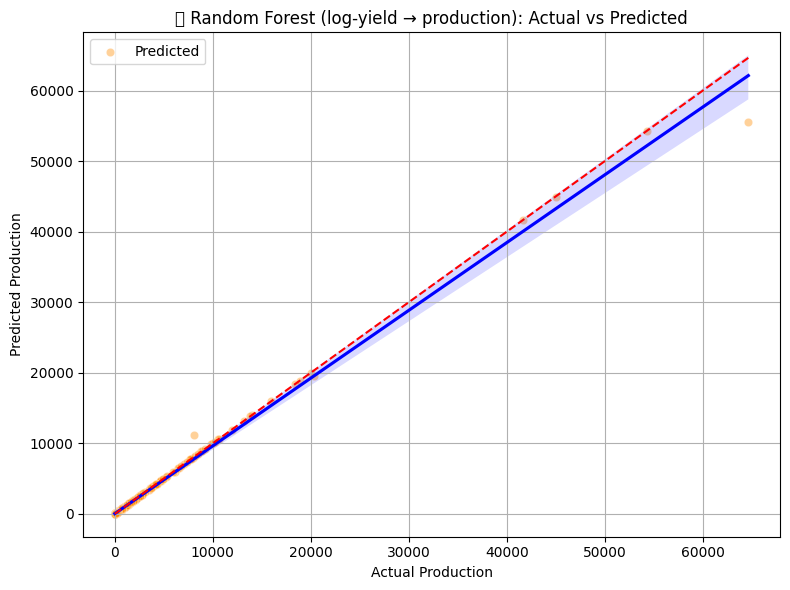

<ipython-input-7-df8de8d8ddb2>:29: UserWarning: Glyph 127795 (\N{DECIDUOUS TREE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127795 (\N{DECIDUOUS TREE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


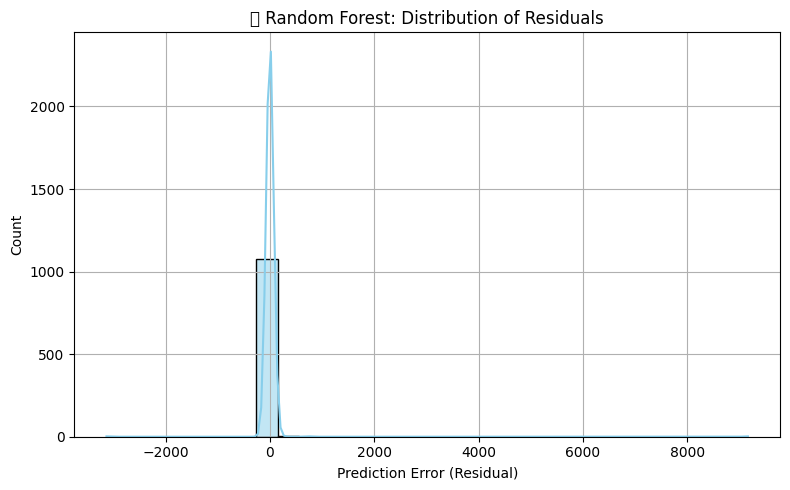

                    district  crop_species  year  production  planted_area  \
1893                   Jasin       Langsat  2017   8079.0710         42.00   
7831  Seberang Perai Selatan  Ladys Finger  2017    746.9787          6.00   
1655              Gua Musang        Tomato  2017  64657.3390        598.65   
9504                   Tenom        Banana  2017  20285.2000        361.10   
1300                   Other      Cucumber  2017   6141.0000        110.70   

           yield  log_yield  log_area  prod_per_area  mean_district_yield  
1893  192.358829   5.264548  3.761200     192.358829         1.275334e+01  
7831  124.496429   4.832277  1.945910     124.496429         2.634663e+01  
1655  108.005243   4.691396  6.396346     108.005243         1.381045e+04  
9504   56.176128   4.046136  5.891920      56.176128         9.843438e+00  
1300   55.474254   4.033785  4.715817      55.474254         7.685002e+07  


<ipython-input-7-df8de8d8ddb2>:52: UserWarning: Glyph 127795 (\N{DECIDUOUS TREE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127795 (\N{DECIDUOUS TREE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


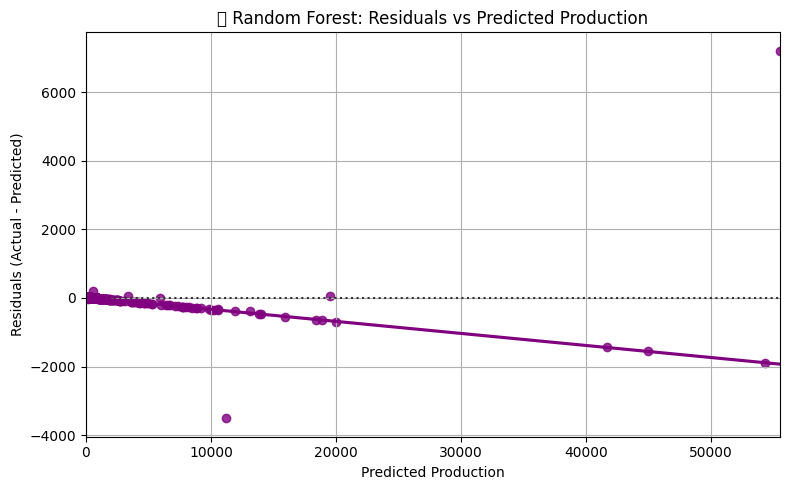

In [ ]:
# Visualizations (Random Forest)

# Scatterplot – Actual vs Predicted
plt.figure(figsize=(8, 6))
sns.scatterplot(x=true_production, y=predicted_production, alpha=0.4, color='darkorange', label='Predicted')
sns.regplot(x=true_production, y=predicted_production, scatter=False, color='blue', label='Trend')
plt.plot(
    [true_production.min(), true_production.max()],
    [true_production.min(), true_production.max()],
    'r--',
    label='Ideal Line (y = x)'
)
plt.xlabel('Actual Production')
plt.ylabel('Predicted Production')
plt.title('🌳 Random Forest (log-yield → production): Actual vs Predicted')
plt.grid(True)
plt.tight_layout()
plt.show()

# Residual Analysis
residuals = true_production - predicted_production

# Residual Histogram
plt.figure(figsize=(8, 5))
sns.histplot(residuals, kde=True, color='skyblue', bins=30)
plt.title('🌳 Random Forest: Distribution of Residuals')
plt.xlabel('Prediction Error (Residual)')
plt.grid(True)
plt.tight_layout()
plt.show()

# Calculate residuals as before
residuals = true_production - predicted_production

# Create a pandas Series with residuals and the original index
residuals_series = pd.Series(residuals, index=X_test.index)

# Select top 5 residuals by absolute value
large_residuals = residuals_series.abs().sort_values(ascending=False).head(5)

# Display the rows in the merged_df corresponding to those large residuals
print(merged_df.loc[large_residuals.index].sort_values(by='yield', ascending=False))


# Residuals vs Predicted
plt.figure(figsize=(8, 5))
sns.residplot(x=predicted_production, y=residuals, lowess=True, color="purple")
plt.title("🌳 Random Forest: Residuals vs Predicted Production")
plt.xlabel("Predicted Production")
plt.ylabel("Residuals (Actual - Predicted)")
plt.grid(True)
plt.tight_layout()
plt.show()

End of Random Forest Regressor


---





---


Model 2 - Decision Tree Regressor 🌴

In [ ]:
from sklearn.tree import DecisionTreeRegressor

# ------------------ ⚙️ Pre-Tuning Evaluation (Baseline Decision Tree) ------------------ #
# Train baseline Decision Tree with default hyperparameters
baseline_dt = DecisionTreeRegressor(random_state=42)
baseline_dt.fit(X_train, y_train)

# Predict and evaluate
baseline_dt_pred_yield = np.expm1(baseline_dt.predict(X_test))
baseline_dt_pred_production = baseline_dt_pred_yield * pa_test.values
baseline_dt_true_production = np.expm1(y_test) * pa_test.values

# Evaluation metrics for baseline Decision Tree
baseline_dt_mae = mean_absolute_error(baseline_dt_true_production, baseline_dt_pred_production)
baseline_dt_rmse = np.sqrt(mean_squared_error(baseline_dt_true_production, baseline_dt_pred_production))
baseline_dt_r2 = r2_score(baseline_dt_true_production, baseline_dt_pred_production)

# Print baseline evaluation
print("\n🧪 Baseline Decision Tree Evaluation (before tuning):")
print(f"R² Score        : {baseline_dt_r2:.3f}")
print(f"MAE (tonnes)    : {baseline_dt_mae:.2f}")
print(f"RMSE (tonnes)   : {baseline_dt_rmse:.2f}")

# Hyperparameter tuning and training of Decision Tree Regressor using RandomizedSearchCV
dt_params = {
    # Maximum depth of the tree (controls model complexity and overfitting)
    'max_depth': [5, 10, 15, 20, None],
    # Minimum number of samples required to split an internal node (controls splitting)
    'min_samples_split': [2, 5, 10, 15],
    # Minimum number of samples required to be at a leaf node (controls leaf size)
    'min_samples_leaf': [1, 2, 4, 8],
    # Number of features to consider when looking for the best split
    'max_features': ['sqrt', None]
}

# Initialize RandomizedSearchCV to efficiently search over the hyperparameter space
dt_random = RandomizedSearchCV(
    estimator=DecisionTreeRegressor(random_state=42),  # Decision Tree with fixed random seed for reproducibility
    param_distributions=dt_params,                     # Hyperparameters to tune
    n_iter=20,                                         # Number of random hyperparameter sets to evaluate
    cv=3,                                              # 3-fold cross-validation to validate model during tuning
    scoring='neg_root_mean_squared_error',             # Using negative RMSE as scoring metric (higher is better)
    n_jobs=-1,                                         # Using all CPU cores for faster computation
    verbose=1,                                         # Shows progress during hyperparameter search
    random_state=42                                    # Fix random seed for reproducibility of search results
)

# Perform hyperparameter tuning by fitting on training data
dt_random.fit(X_train, y_train)

# Extract the best performing model from the search
best_dt = dt_random.best_estimator_

# Predict log-transformed yield and convert back to yield scale
predicted_yield = np.expm1(best_dt.predict(X_test))

# Convert true log-transformed yields back to production values by multiplying by planted area
true_production = np.expm1(y_test) * pa_test.values

# Calculate predicted production by multiplying predicted yield with planted area
predicted_production = predicted_yield * pa_test.values

# Calculate evaluation metrics to compare true and predicted production values:
r2 = r2_score(true_production, predicted_production)
mae = mean_absolute_error(true_production, predicted_production)
rmse = np.sqrt(mean_squared_error(true_production, predicted_production))

# Print out final evaluation results and best hyperparameters
print("\n🌴 Final Evaluation with Decision Tree:")
print(f"Best Parameters : {dt_random.best_params_}")  # Display best hyperparameter combination found
print(f"R² Score        : {r2:.3f}")                   # R² score with 3 decimal places
print(f"MAE (tonnes)    : {mae:.2f}")                  # MAE rounded to 2 decimals
print(f"RMSE (tonnes)   : {rmse:.2f}")                 # RMSE rounded to 2 decimals

# 📦 Store results for combined plotting later
model_name = "Decision Tree"
all_results[model_name] = {
    'pred': predicted_production,
    'true': true_production,
    'r2': r2,
    'mae': mae,
    'rmse': rmse,
    'residuals': true_production - predicted_production
}


🧪 Baseline Decision Tree Evaluation (before tuning):
R² Score        : 0.988
MAE (tonnes)    : 18.36
RMSE (tonnes)   : 413.19
Fitting 3 folds for each of 20 candidates, totalling 60 fits

🌴 Final Evaluation with Decision Tree:
Best Parameters : {'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': None, 'max_depth': 15}
R² Score        : 0.996
MAE (tonnes)    : 10.53
RMSE (tonnes)   : 234.53


<ipython-input-9-f51f86c116aa>:18: UserWarning: Glyph 127795 (\N{DECIDUOUS TREE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127795 (\N{DECIDUOUS TREE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


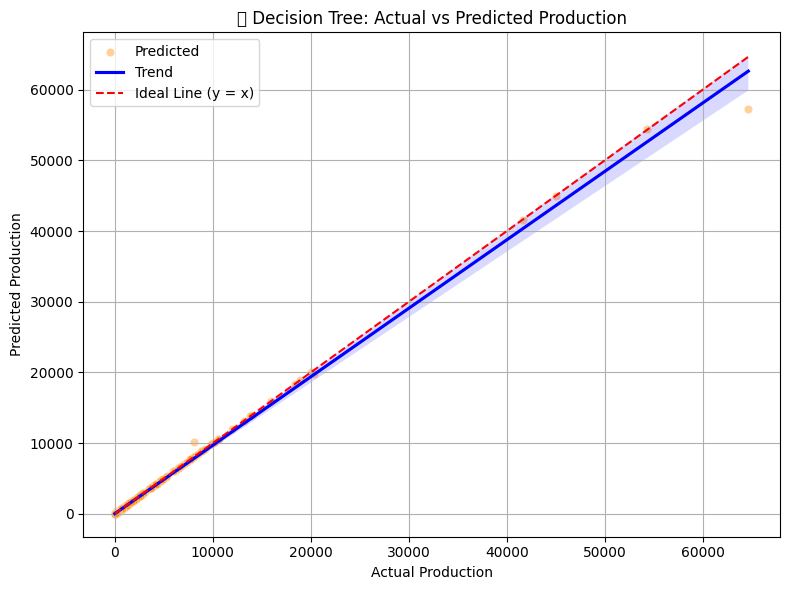

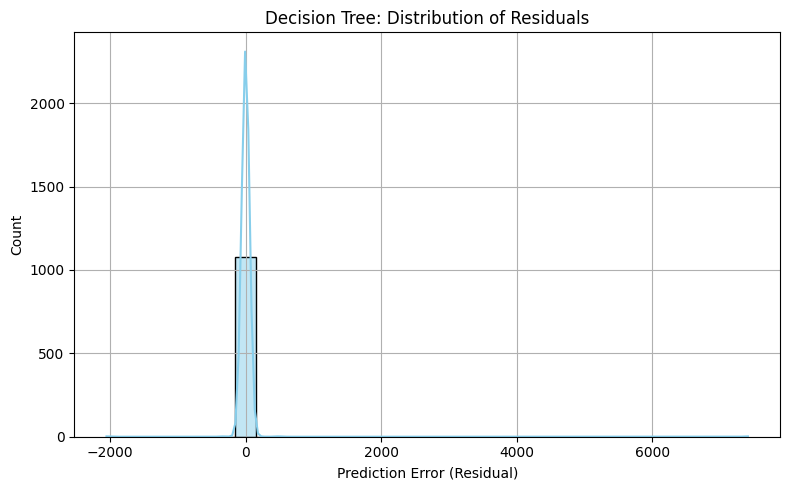

                    district  crop_species  year  production  planted_area  \
1034                    Bera      Mushroom  2017     97.5100          0.50   
1893                   Jasin       Langsat  2017   8079.0710         42.00   
7831  Seberang Perai Selatan  Ladys Finger  2017    746.9787          6.00   
1655              Gua Musang        Tomato  2017  64657.3390        598.65   
9504                   Tenom        Banana  2017  20285.2000        361.10   

           yield  log_yield  log_area  prod_per_area  mean_district_yield  
1034  195.019610   5.278215  0.405465     195.019610         1.149067e+08  
1893  192.358829   5.264548  3.761200     192.358829         1.275334e+01  
7831  124.496429   4.832277  1.945910     124.496429         2.634663e+01  
1655  108.005243   4.691396  6.396346     108.005243         1.381045e+04  
9504   56.176128   4.046136  5.891920      56.176128         9.843438e+00  


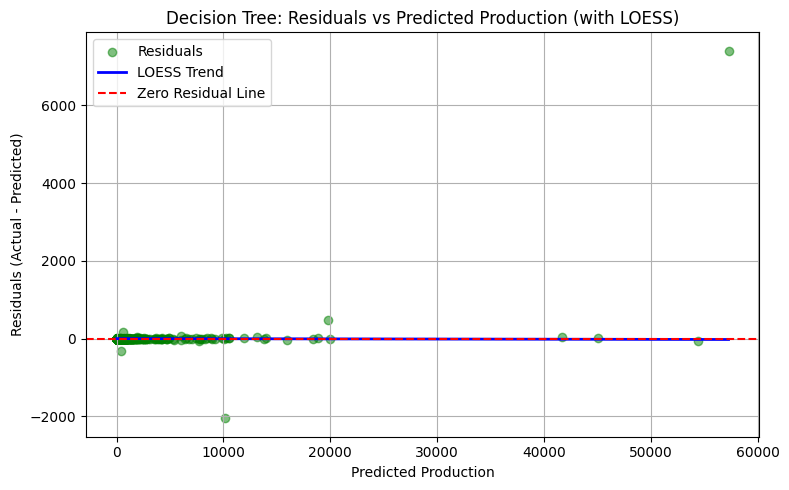

In [ ]:
# Visualizations (Decision Tree)

# Scatterplot – Actual vs Predicted
plt.figure(figsize=(8, 6))
sns.scatterplot(x=true_production, y=predicted_production, alpha=0.4, color='darkorange', label='Predicted')
sns.regplot(x=true_production, y=predicted_production, scatter=False, color='blue', label='Trend')
plt.plot(
    [true_production.min(), true_production.max()],
    [true_production.min(), true_production.max()],
    'r--',
    label='Ideal Line (y = x)'
)
plt.xlabel('Actual Production')
plt.ylabel('Predicted Production')
plt.title('🌳 Decision Tree: Actual vs Predicted Production')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Residual Analysis
residuals = true_production - predicted_production

# Residual Histogram
plt.figure(figsize=(8, 5))
sns.histplot(residuals, kde=True, color='skyblue', bins=30)
plt.title('Decision Tree: Distribution of Residuals')
plt.xlabel('Prediction Error (Residual)')
plt.grid(True)
plt.tight_layout()
plt.show()

# Calculate residuals as before
residuals = true_production - predicted_production

# Create a pandas Series with residuals and the original index
residuals_series = pd.Series(residuals, index=X_test.index)

# Select top 5 residuals by absolute value
large_residuals = residuals_series.abs().sort_values(ascending=False).head(5)

# Display the rows in the merged_df corresponding to those large residuals
print(merged_df.loc[large_residuals.index].sort_values(by='yield', ascending=False))

# Residuals vs Predicted
from statsmodels.nonparametric.smoothers_lowess import lowess

# Fit LOESS for Decision Tree
smoothed_dt = lowess(residuals, predicted_production, frac=0.3)

# Plot
plt.figure(figsize=(8, 5))
plt.scatter(predicted_production, residuals, alpha=0.5, color='green', label='Residuals')
plt.plot(smoothed_dt[:, 0], smoothed_dt[:, 1], color='blue', linewidth=2, label='LOESS Trend')
plt.axhline(0, color='red', linestyle='--', label='Zero Residual Line')
plt.title("Decision Tree: Residuals vs Predicted Production (with LOESS)")
plt.xlabel("Predicted Production")
plt.ylabel("Residuals (Actual - Predicted)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()



End of Decision Tree Regressor


---





---



Model 3 - XGBoost (Extreme Gradient Boosting) 💥



In [ ]:
import numpy as np
from xgboost import XGBRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Define XGBRegressor
xgb_reg = XGBRegressor(objective='reg:squarederror', seed=42)

# ------------------ ⚙️ Pre-Tuning Evaluation ------------------ #
# Train baseline XGBoost with default hyperparameters
baseline_xgb = XGBRegressor(objective='reg:squarederror', seed=42)
baseline_xgb.fit(X_train, y_train)

# Predict and inverse log-transform
baseline_pred_yield = np.expm1(baseline_xgb.predict(X_test))
baseline_pred_production = baseline_pred_yield * pa_test.values
baseline_true_production = np.expm1(y_test) * pa_test.values

# Evaluate baseline
baseline_mae = mean_absolute_error(baseline_true_production, baseline_pred_production)
baseline_rmse = np.sqrt(mean_squared_error(baseline_true_production, baseline_pred_production))
baseline_r2 = r2_score(baseline_true_production, baseline_pred_production)

# Print baseline evaluation
print("\n🧪 Baseline XGBoost Evaluation (before tuning):")
print(f"R² Score        : {baseline_r2:.3f}")
print(f"MAE (tonnes)    : {baseline_mae:.2f}")
print(f"RMSE (tonnes)   : {baseline_rmse:.2f}")

# Define parameter space for XGBoost
param_grid = {
    'learning_rate': [0.03, 0.04, 0.05, 0.06, 0.07],     # Controls how quickly the model adapts (smaller = slower but more accurate)
    'max_depth': [2, 3, 4],                              # Maximum depth of each tree
    'min_child_weight': [2, 3, 4],                       # Minimum sum of instance weight needed in a child
    'subsample': [0.75, 0.8, 0.85],                      # Fraction of training samples used per tree
    'colsample_bytree': [0.9, 1.0],                      # Fraction of features used per tree
    'n_estimators': [250, 300, 350],                     # Number of boosting rounds (trees)
    'reg_alpha': [0.05, 0.1, 0.2],                       # L1 regularization (sparsity)
    'reg_lambda': [0.8, 1.0, 1.2],                       # L2 regularization (ridge penalty)
}

# Perform randomized search
random_search = RandomizedSearchCV(
    estimator=xgb_reg,                                   # Base XGBoost regressor
    param_distributions=param_grid,                      # Parameter grid to sample from
    n_iter=30,                                            # Number of random combinations to try
    cv=5,                                                 # 5-fold cross-validation for reliability
    scoring='neg_mean_squared_error',                    # Performance metric (lower is better)
    verbose=1,                                            # Print progress during search
    random_state=42,                                     # Reproducibility
    n_jobs=-1                                             # Use all available CPU cores
)

# Fit the model
random_search.fit(X_train, y_train)

# Get best model
best_model = random_search.best_estimator_
print("\n✅ Best Parameters:", random_search.best_params_)

# Predict and inverse log-transform
predicted_yield = np.expm1(best_model.predict(X_test))

# Calculate production
true_production = np.expm1(y_test) * pa_test.values
predicted_production = predicted_yield * pa_test.values

# Evaluate
r2 = r2_score(true_production, predicted_production)
mae = mean_absolute_error(true_production, predicted_production)
rmse = np.sqrt(mean_squared_error(true_production, predicted_production))

# Output evaluations
print("\n💥 Tuned XGBoost Model Evaluation:")               # Display best hyperparameter combination found
print(f"R² Score        : {r2:.3f}")                   # R² score with 3 decimal places
print(f"MAE (tonnes)    : {mae:.2f}")                  # MAE rounded to 2 decimals
print(f"RMSE (tonnes)   : {rmse:.2f}")                 # RMSE rounded to 2 decimals

# 📦 Store results for combined plotting later
model_name = "XGBoost"
all_results[model_name] = {
    'pred': predicted_production,
    'true': true_production,
    'r2': baseline_r2,
    'mae': baseline_mae,
    'rmse': baseline_rmse,
    'residuals': true_production - predicted_production
}


🧪 Baseline XGBoost Evaluation (before tuning):
R² Score        : 0.997
MAE (tonnes)    : 13.38
RMSE (tonnes)   : 191.90
Fitting 5 folds for each of 30 candidates, totalling 150 fits

✅ Best Parameters: {'subsample': 0.85, 'reg_lambda': 1.2, 'reg_alpha': 0.1, 'n_estimators': 300, 'min_child_weight': 2, 'max_depth': 3, 'learning_rate': 0.05, 'colsample_bytree': 1.0}

💥 Tuned XGBoost Model Evaluation:
R² Score        : 0.983
MAE (tonnes)    : 28.34
RMSE (tonnes)   : 480.91


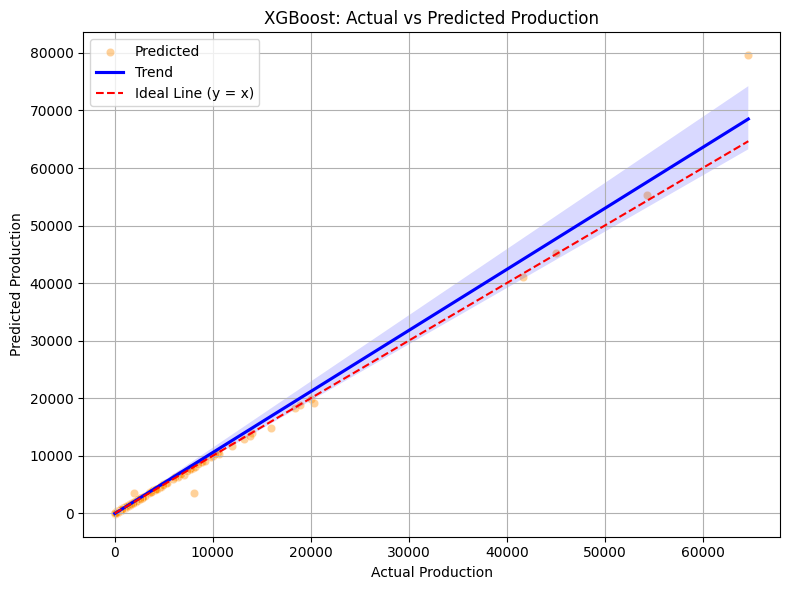

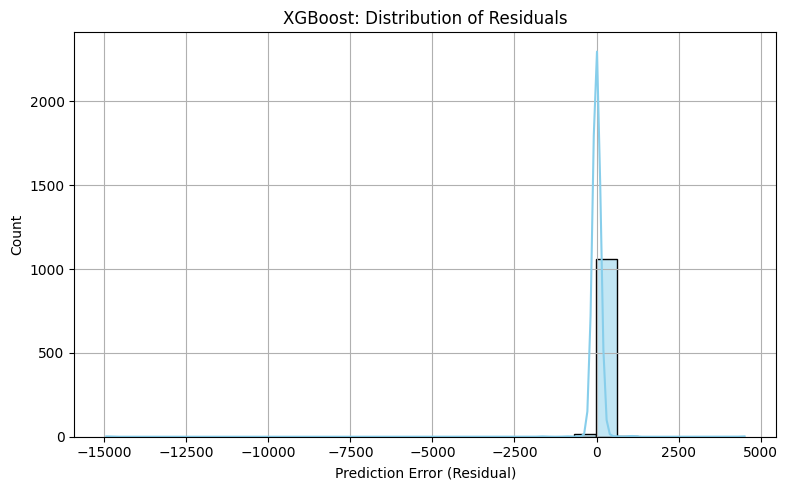

           district crop_species  year  production  planted_area       yield  \
1893          Jasin      Langsat  2017   8079.0710         42.00  192.358829   
1655     Gua Musang       Tomato  2017  64657.3390        598.65  108.005243   
9504          Tenom       Banana  2017  20285.2000        361.10   56.176128   
600      Batu Pahat       Papaya  2017  15952.8500        339.00   47.058554   
5576  Melaka Tengah        Guava  2017   1969.4404         45.32   43.456319   

      log_yield  log_area  prod_per_area  mean_district_yield  
1893   5.264548  3.761200     192.358829            12.753340  
1655   4.691396  6.396346     108.005243         13810.451083  
9504   4.046136  5.891920      56.176128             9.843438  
600    3.872420  5.828946      47.058554            13.228823  
5576   3.794507  3.835574      43.456319         53072.690574  


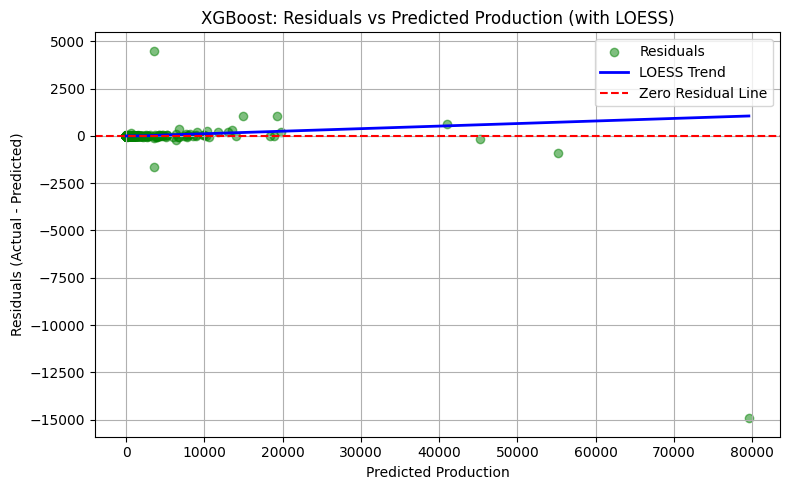

In [ ]:
# Visualizations (XGBoost)

# Scatterplot – Actual vs Predicted Production
plt.figure(figsize=(8, 6))
sns.scatterplot(x=true_production, y=predicted_production, alpha=0.4, color='darkorange', label='Predicted')
sns.regplot(x=true_production, y=predicted_production, scatter=False, color='blue', label='Trend')
plt.plot(
    [true_production.min(), true_production.max()],
    [true_production.min(), true_production.max()],
    'r--',
    label='Ideal Line (y = x)'
)
plt.xlabel('Actual Production')
plt.ylabel('Predicted Production')
plt.title('XGBoost: Actual vs Predicted Production')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Residual Analysis - Distribution of Prediction Errors
residuals = true_production - predicted_production

# Residual Histogram
plt.figure(figsize=(8, 5))
sns.histplot(residuals, kde=True, color='skyblue', bins=30)
plt.title('XGBoost: Distribution of Residuals')
plt.xlabel('Prediction Error (Residual)')
plt.grid(True)
plt.tight_layout()
plt.show()

# Create a pandas Series for residuals with test set index
residuals_series = pd.Series(residuals, index=X_test.index)

# Identify top 5 largest residuals by absolute value for error inspection
large_residuals = residuals_series.abs().sort_values(ascending=False).head(5)

# Display corresponding rows in merged_df for these large residual errors
print(merged_df.loc[large_residuals.index].sort_values(by='yield', ascending=False))


from statsmodels.nonparametric.smoothers_lowess import lowess

# Fit LOESS
smoothed = lowess(residuals, predicted_production)

# Plot residuals
plt.figure(figsize=(8, 5))
plt.scatter(predicted_production, residuals, alpha=0.5, color='green', label='Residuals')
plt.plot(smoothed[:, 0], smoothed[:, 1], color='blue', linewidth=2, label='LOESS Trend')
plt.axhline(0, color='red', linestyle='--', label='Zero Residual Line')
plt.title("XGBoost: Residuals vs Predicted Production (with LOESS)")
plt.xlabel("Predicted Production")
plt.ylabel("Residuals (Actual - Predicted)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


 End of XGBoost (Extreme Gradient Boosting)

---





---


Model 4 - LightGBM (Light Gradient Boosting Machine) 💡

In [ ]:
# Import LightGBM regressor and model selection tools
import lightgbm as lgb
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import uniform, randint

# Fix spaces in column names (for LightGBM)
X.columns = X.columns.str.replace(' ', '_')

# Split data into training and testing (no stratify because regression target)
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test, pa_train, pa_test = train_test_split(
    X, y, planted_area_values, test_size=0.2, random_state=42)

# --- 🌱 Baseline LightGBM Model (Before Hyperparameter Tuning) ---
baseline_lgb = lgb.LGBMRegressor(objective='regression', random_state=42)
baseline_lgb.fit(X_train, y_train)

# Predict and inverse transform yield
baseline_pred_yield = np.expm1(baseline_lgb.predict(X_test))

# Compute production
baseline_pred_production = baseline_pred_yield * pa_test.values
baseline_true_production = np.expm1(y_test) * pa_test.values

# Evaluate baseline model
baseline_r2 = r2_score(baseline_true_production, baseline_pred_production)
baseline_mae = mean_absolute_error(baseline_true_production, baseline_pred_production)
baseline_rmse = np.sqrt(mean_squared_error(baseline_true_production, baseline_pred_production))

print("\n🔍 Baseline LightGBM Evaluation (Before Tuning):")
print(f"R² Score        : {baseline_r2:.3f}")
print(f"MAE (tonnes)    : {baseline_mae:.2f}")
print(f"RMSE (tonnes)   : {baseline_rmse:.2f}")

# Parameter grid for RandomizedSearchCV
param_grid = {
    'learning_rate': [0.01, 0.03, 0.05],         # Controls step size (smaller = slower learning, but more precise)
    'n_estimators': [200, 300, 400],             # Number of boosting rounds (trees)
    'max_depth': [5, 7, 9],                      # Maximum depth of each tree (controls complexity)
    'num_leaves': [31, 50, 70],                  # Number of leaves per tree (more leaves = more complex model)
    'min_child_samples': [1, 3, 5],              # Minimum number of samples required to form a leaf
    'subsample': [0.8, 0.9, 1.0],                # Fraction of training data used for each boosting round (row sampling)
    'colsample_bytree': [0.8, 0.9, 1.0],         # Fraction of features used per tree (feature sampling)
    'reg_lambda': [0, 0.01, 0.1],                # L2 regularization (helps reduce overfitting)
    'reg_alpha': [0.1, 0.3, 0.5]                 # L1 regularization (helps with feature selection)
}

# Initialize LightGBM regressor
lgb_model = lgb.LGBMRegressor(objective='regression', random_state=42)

# Hyperparameter tuning using randomized search with 3-fold cross-validation
random_search_lgb = RandomizedSearchCV(
    estimator=lgb_model,                         # Base LightGBM regressor
    param_distributions=param_grid,              # Search space for hyperparameters
    n_iter=30,                                   # Number of random combinations to try
    scoring='neg_mean_squared_error',            # Evaluation metric (lower is better)
    cv=3,                                        # 3-fold cross-validation
    verbose=1,                                   # Show progress during search
    random_state=42,                             # For reproducibility
    n_jobs=-1                                    # Use all available CPU cores
)

# Fit model with hyperparameter tuning
random_search_lgb.fit(X_train, y_train)

# Best model and parameters
best_lgb_model = random_search_lgb.best_estimator_
print("✅ Best Parameters:", random_search_lgb.best_params_)

# Early stopping on validation set using best parameters
X_train_inner, X_val, y_train_inner, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=42)

best_lgb_model.fit(
    X_train_inner, y_train_inner,
    eval_set=[(X_val, y_val)],
    eval_metric=['rmse', 'mae'],
    callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=20)]
)

# Converts from log_yield to yield
predicted_yield = np.expm1(best_lgb_model.predict(X_test))

# Compute production from predicted yield
predicted_production = predicted_yield * pa_test.values

# True production from actual yield
true_production = np.expm1(y_test) * pa_test.values

# Evaluate model
r2 = r2_score(true_production, predicted_production)
mae = mean_absolute_error(true_production, predicted_production)
rmse = np.sqrt(mean_squared_error(true_production, predicted_production))

print(f"\n💡 LightGBM Model Evaluation:")              # Display best hyperparameter combination found
print(f"R² Score        : {r2:.3f}")                   # R² score with 3 decimal places
print(f"MAE (tonnes)    : {mae:.2f}")                  # MAE rounded to 2 decimals
print(f"RMSE (tonnes)   : {rmse:.2f}")                 # RMSE rounded to 2 decimals

# 📦 Store results for combined plotting later
model_name = "LightGBM"
all_results[model_name] = {
    'pred': predicted_production,
    'true': true_production,
    'r2': r2,
    'mae': mae,
    'rmse': rmse,
    'residuals': true_production - predicted_production
}

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000720 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1042
[LightGBM] [Info] Number of data points in the train set: 4326, number of used features: 193
[LightGBM] [Info] Start training from score 2.040285

🔍 Baseline LightGBM Evaluation (Before Tuning):
R² Score        : 0.940
MAE (tonnes)    : 47.36
RMSE (tonnes)   : 910.25
Fitting 3 folds for each of 30 candidates, totalling 90 fits
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000273 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1152
[LightGBM] [Info] Number of data points in the train set: 4326, number of used features: 248
[LightGBM] [Info] Start training from score 2.040285
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain,

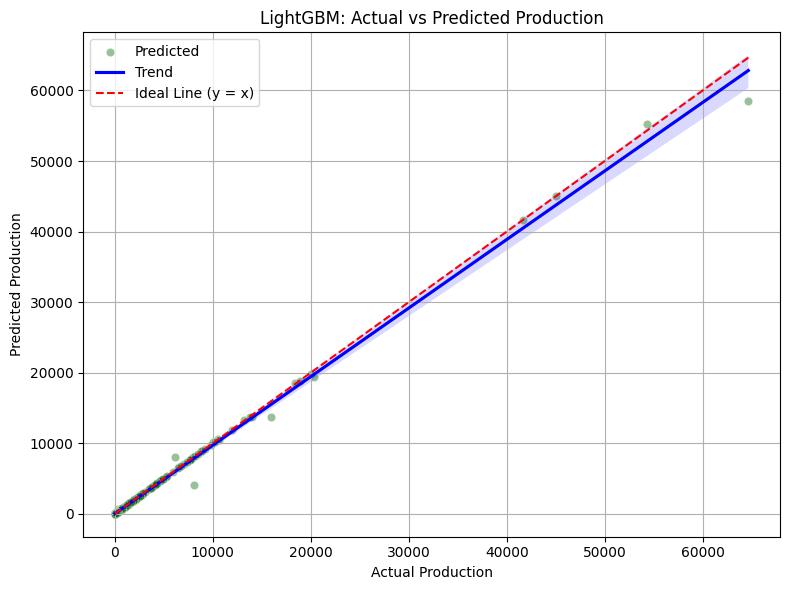

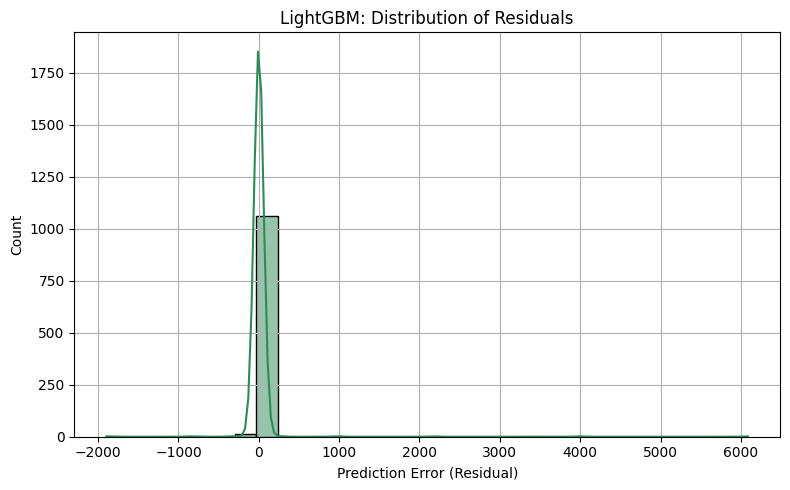

        district crop_species  year  production  planted_area       yield  \
1893       Jasin      Langsat  2017    8079.071         42.00  192.358829   
1655  Gua Musang       Tomato  2017   64657.339        598.65  108.005243   
9504       Tenom       Banana  2017   20285.200        361.10   56.176128   
1300       Other     Cucumber  2017    6141.000        110.70   55.474254   
600   Batu Pahat       Papaya  2017   15952.850        339.00   47.058554   

      log_yield  log_area  prod_per_area  mean_district_yield  
1893   5.264548  3.761200     192.358829         1.275334e+01  
1655   4.691396  6.396346     108.005243         1.381045e+04  
9504   4.046136  5.891920      56.176128         9.843438e+00  
1300   4.033785  4.715817      55.474254         7.685002e+07  
600    3.872420  5.828946      47.058554         1.322882e+01  


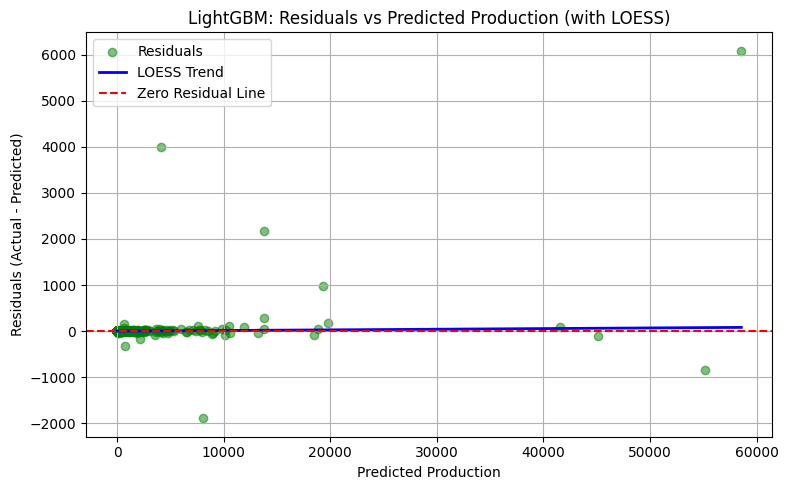

In [ ]:
# Visualizations (LightGBM)

# Scatterplot – Actual vs Predicted Production
plt.figure(figsize=(8, 6))
sns.scatterplot(x=true_production, y=predicted_production, alpha=0.4, color='darkgreen', label='Predicted')
sns.regplot(x=true_production, y=predicted_production, scatter=False, color='blue', label='Trend')
plt.plot(
    [true_production.min(), true_production.max()],
    [true_production.min(), true_production.max()],
    'r--',
    label='Ideal Line (y = x)'
)
plt.xlabel('Actual Production')
plt.ylabel('Predicted Production')
plt.title('LightGBM: Actual vs Predicted Production')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Residual Analysis - Distribution of Prediction Errors
residuals_lgbm = true_production - predicted_production

# Residual Histogram
plt.figure(figsize=(8, 5))
sns.histplot(residuals_lgbm, kde=True, color='seagreen', bins=30)
plt.title('LightGBM: Distribution of Residuals')
plt.xlabel('Prediction Error (Residual)')
plt.grid(True)
plt.tight_layout()
plt.show()

# Create a pandas Series for residuals with test set index
residuals_series_lgbm = pd.Series(residuals_lgbm, index=X_test.index)

# Identify top 5 largest residuals by absolute value for error inspection
large_residuals_lgbm = residuals_series_lgbm.abs().sort_values(ascending=False).head(5)

# Display corresponding rows in merged_df for these large residual errors
print(merged_df.loc[large_residuals_lgbm.index].sort_values(by='yield', ascending=False))


from statsmodels.nonparametric.smoothers_lowess import lowess

# Fit LOESS for LightGBM residuals
smoothed_lgbm = lowess(residuals_lgbm, predicted_production)

# Plot residuals
plt.figure(figsize=(8, 5))
plt.scatter(predicted_production, residuals_lgbm, alpha=0.5, color='green', label='Residuals')
plt.plot(smoothed_lgbm[:, 0], smoothed_lgbm[:, 1], color='blue', linewidth=2, label='LOESS Trend')
plt.axhline(0, color='red', linestyle='--', label='Zero Residual Line')
plt.title("LightGBM: Residuals vs Predicted Production (with LOESS)")
plt.xlabel("Predicted Production")
plt.ylabel("Residuals (Actual - Predicted)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


End of LightGBM (Light Gradient Boosting Machine)


---





---

Model 5 - CatBoost (Categorical Boosting) 🐈

In [ ]:
# Import CatBoost Regressor
!pip install catboost
from catboost import CatBoostRegressor

# ------------------ ⚙️ Pre-Tuning Evaluation (Baseline CatBoost) ------------------ #
# Train baseline CatBoost Regressor with default parameters
baseline_cat = CatBoostRegressor(random_seed=42, verbose=0)
baseline_cat.fit(X_train, y_train)

# Predict and evaluate
baseline_cat_pred_yield = np.expm1(baseline_cat.predict(X_test))
baseline_cat_pred_production = baseline_cat_pred_yield * pa_test.values
baseline_cat_true_production = np.expm1(y_test) * pa_test.values

# Evaluation metrics for baseline CatBoost
baseline_cat_mae = mean_absolute_error(baseline_cat_true_production, baseline_cat_pred_production)
baseline_cat_rmse = np.sqrt(mean_squared_error(baseline_cat_true_production, baseline_cat_pred_production))
baseline_cat_r2 = r2_score(baseline_cat_true_production, baseline_cat_pred_production)

# Print baseline evlauation
print("\n🧪 Baseline CatBoost Evaluation (before tuning):")
print(f"R² Score        : {baseline_cat_r2:.3f}")
print(f"MAE (tonnes)    : {baseline_cat_mae:.2f}")
print(f"RMSE (tonnes)   : {baseline_cat_rmse:.2f}")

# Define the hyperparameter search space for CatBoost Regressor
param_grid_catboost = {
    'learning_rate': [0.025, 0.03, 0.035],       # Step size for each boosting iteration
    'depth': [6, 7, 8],                          # Depth of each tree (controls model complexity)
    'iterations': [250, 300, 350],               # Total number of boosting rounds
    'l2_leaf_reg': [2, 3, 4],                    # L2 regularization to prevent overfitting
    'border_count': [40, 50, 60],                # Number of splits for numerical features (higher = more precise)
    'random_strength': [1, 2, 3]                 # Randomness added to feature selection (helps generalization)
}

# Initialize CatBoost regressor
cat_model = CatBoostRegressor(loss_function='RMSE', random_seed=42, verbose=0)

# Perform hyperparameter tuning using RandomizedSearchCV with 3-fold cross-validation
random_search_cat = RandomizedSearchCV(
    estimator=cat_model,                         # CatBoost regressor to tune
    param_distributions=param_grid_catboost,     # Parameter grid defined above
    n_iter=25,                                   # Number of random combinations to try
    scoring='neg_mean_squared_error',            # Use negative MSE for regression scoring
    cv=3,                                        # 3-fold cross-validation for model robustness
    verbose=1,                                   # Print progress during search
    random_state=42,                             # Ensures reproducible results
    n_jobs=-1                                    # Use all available processors
)

# Fit RandomizedSearchCV on training data
random_search_cat.fit(X_train, y_train)

# Best model and parameters
best_cat_model = random_search_cat.best_estimator_
print("✅ Best CatBoost Parameters:", random_search_cat.best_params_)

# Predict log_transformed yield and convert back to yield scale
predicted_yield = np.expm1(best_cat_model.predict(X_test))

# Convert true log-transformed yields back to production values by multiplying by planted area
true_production = np.expm1(y_test) * pa_test.values

# Calculate predicted production by multiplying predicted yield with planted area
predicted_production = predicted_yield * pa_test.values

# Calculate evaluation metrics to compare true and predicted production values
r2 = r2_score(true_production, predicted_production)
mae = mean_absolute_error(true_production, predicted_production)
rmse = np.sqrt(mean_squared_error(true_production, predicted_production))

# Print out final evaluation results and best hyperparameters
print(f"\n🐈 CatBoost Model Evaluation:")   # Display best hyperparameter combination found
print(f"R² Score        : {r2:.3f}")     # R² score with 3 decimal places
print(f"MAE (tonnes)    : {mae:.2f}")    # MAE rounded to 2 decimals
print(f"RMSE (tonnes)   : {rmse:.2f}")   # RMSE rounded to 2 decimals

# 📦 Store results for combined plotting later
model_name = "CatBoost"
all_results[model_name] = {
    'pred': baseline_cat_pred_production,
    'true': baseline_cat_true_production,
    'r2': baseline_cat_r2,
    'mae': baseline_cat_mae,
    'rmse': baseline_cat_rmse,
    'residuals': baseline_cat_true_production - baseline_cat_pred_production
}


🧪 Baseline CatBoost Evaluation (before tuning):
R² Score        : 0.980
MAE (tonnes)    : 34.04
RMSE (tonnes)   : 526.83
Fitting 3 folds for each of 25 candidates, totalling 75 fits
✅ Best CatBoost Parameters: {'random_strength': 2, 'learning_rate': 0.03, 'l2_leaf_reg': 2, 'iterations': 350, 'depth': 7, 'border_count': 50}

🐈 CatBoost Model Evaluation:
R² Score        : 0.969
MAE (tonnes)    : 59.97
RMSE (tonnes)   : 651.49


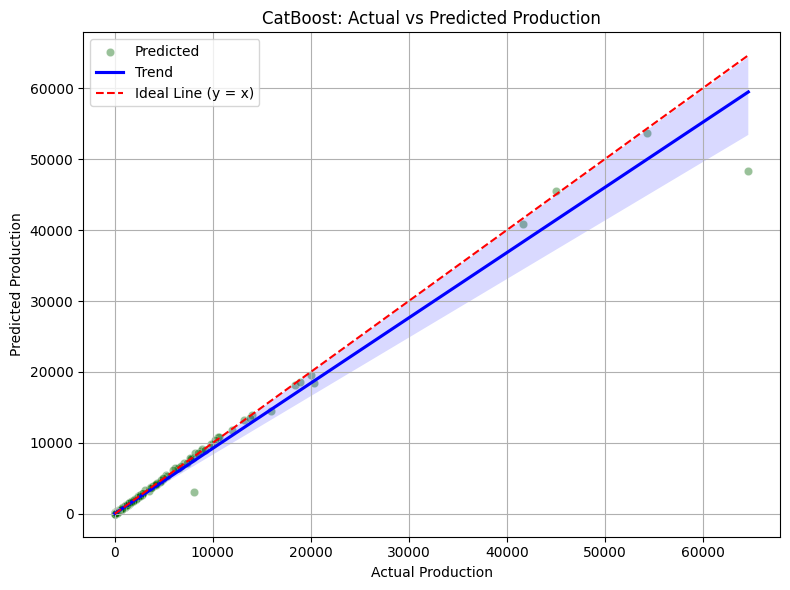

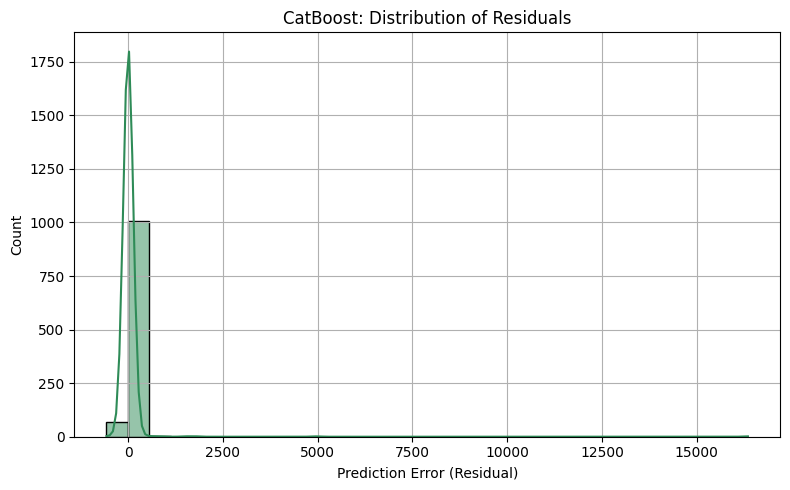

        district crop_species  year  production  planted_area       yield  \
1893       Jasin      Langsat  2017    8079.071         42.00  192.358829   
1655  Gua Musang       Tomato  2017   64657.339        598.65  108.005243   
9504       Tenom       Banana  2017   20285.200        361.10   56.176128   
600   Batu Pahat       Papaya  2017   15952.850        339.00   47.058554   
7258        Raub       Banana  2017   41681.883       2396.57   17.392308   

      log_yield  log_area  prod_per_area  mean_district_yield  
1893   5.264548  3.761200     192.358829            12.753340  
1655   4.691396  6.396346     108.005243         13810.451083  
9504   4.046136  5.891920      56.176128             9.843438  
600    3.872420  5.828946      47.058554            13.228823  
7258   2.911933  7.782211      17.392308          7366.333759  


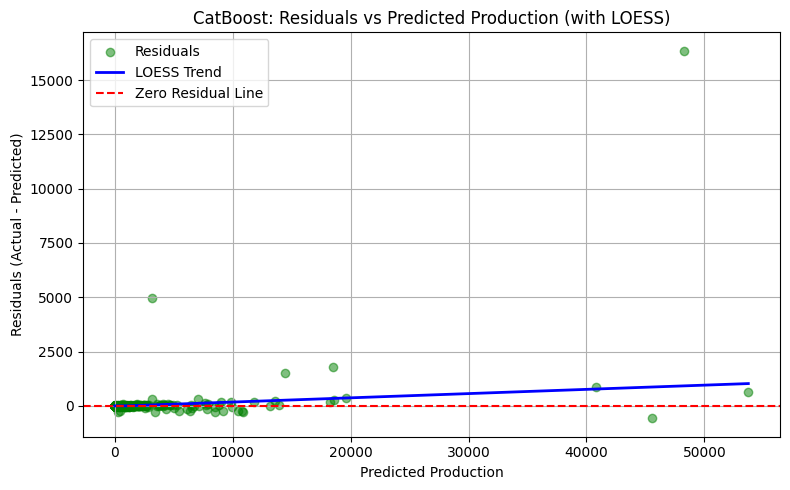

In [ ]:
# Visualizations (CatBoost)

# Scatterplot – Actual vs Predicted Production
plt.figure(figsize=(8, 6))
sns.scatterplot(x=all_results["CatBoost"]['true'], y=all_results["CatBoost"]['pred'], alpha=0.4, color='darkgreen', label='Predicted')
sns.regplot(x=all_results["CatBoost"]['true'], y=all_results["CatBoost"]['pred'], scatter=False, color='blue', label='Trend')
plt.plot(
    [all_results["CatBoost"]['true'].min(), all_results["CatBoost"]['true'].max()],
    [all_results["CatBoost"]['true'].min(), all_results["CatBoost"]['true'].max()],
    'r--',
    label='Ideal Line (y = x)'
)
plt.xlabel('Actual Production')
plt.ylabel('Predicted Production')
plt.title('CatBoost: Actual vs Predicted Production')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Residual Analysis - Distribution of Prediction Errors
residuals_cb = all_results["CatBoost"]['residuals']

# Residual Histogram
plt.figure(figsize=(8, 5))
sns.histplot(residuals_cb, kde=True, color='seagreen', bins=30)
plt.title('CatBoost: Distribution of Residuals')
plt.xlabel('Prediction Error (Residual)')
plt.grid(True)
plt.tight_layout()
plt.show()

# Create a pandas Series for residuals with test set index
residuals_series_cb = pd.Series(residuals_cb, index=X_test.index)

# Identify top 5 largest residuals by absolute value for error inspection
large_residuals_cb = residuals_series_cb.abs().sort_values(ascending=False).head(5)

# Display corresponding rows in merged_df for these large residual errors
print(merged_df.loc[large_residuals_cb.index].sort_values(by='yield', ascending=False))

from statsmodels.nonparametric.smoothers_lowess import lowess

# Fit LOESS for CatBoost residuals
smoothed_cb = lowess(residuals_cb, all_results["CatBoost"]['pred'])

# Plot residuals
plt.figure(figsize=(8, 5))
plt.scatter(all_results["CatBoost"]['pred'], residuals_cb, alpha=0.5, color='green', label='Residuals')
plt.plot(smoothed_cb[:, 0], smoothed_cb[:, 1], color='blue', linewidth=2, label='LOESS Trend')
plt.axhline(0, color='red', linestyle='--', label='Zero Residual Line')
plt.title("CatBoost: Residuals vs Predicted Production (with LOESS)")
plt.xlabel("Predicted Production")
plt.ylabel("Residuals (Actual - Predicted)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()




---


**Descriptive Analytics - Dataset-based Visualizations**


---



<ipython-input-20-965b8844ed7f>:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_district_area.values, y=top_district_area.index, palette='viridis')


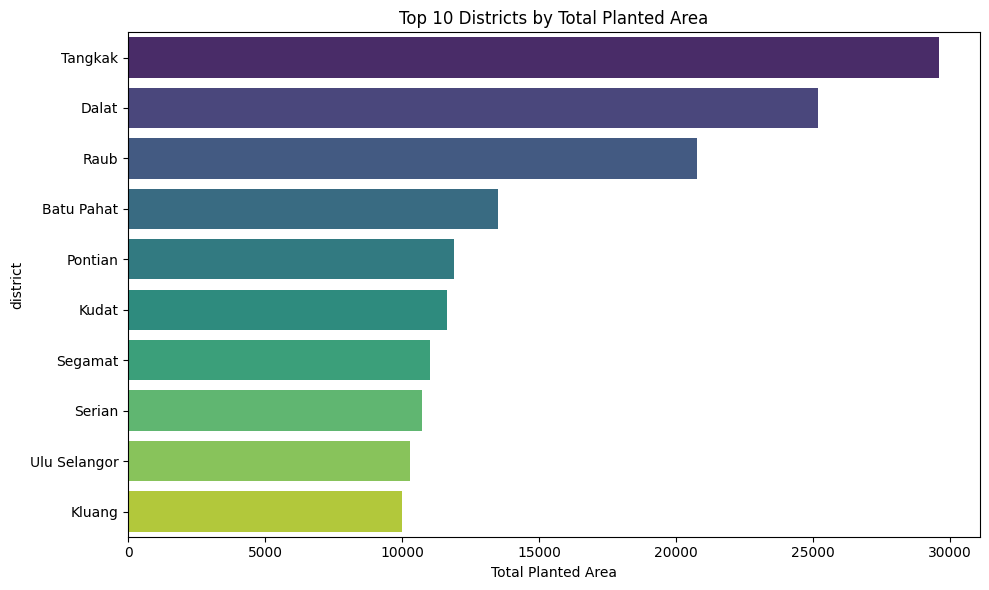

<ipython-input-20-965b8844ed7f>:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_districts_prod.values, y=top_districts_prod.index, palette='magma')


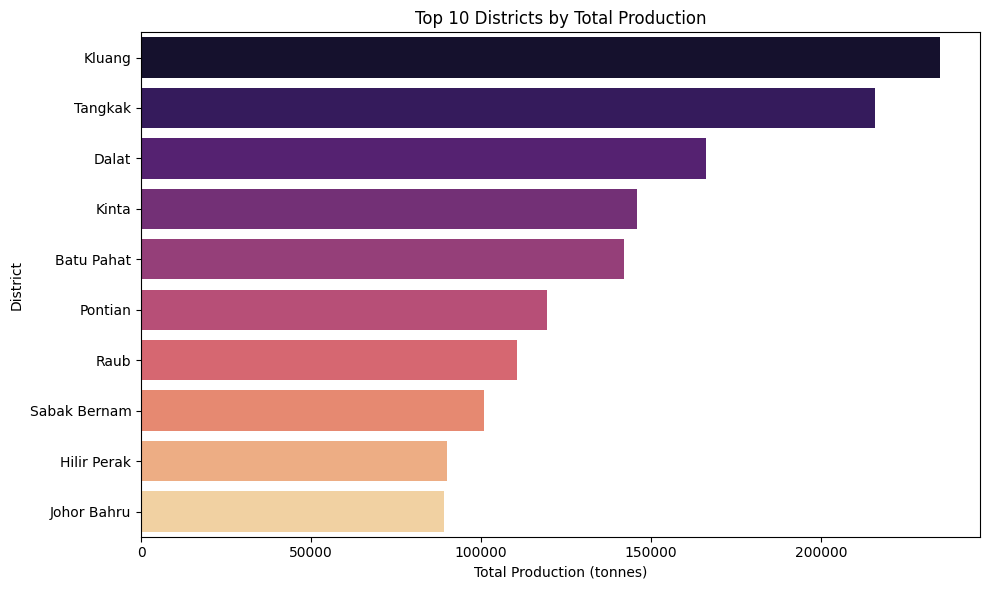

<ipython-input-20-965b8844ed7f>:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_district_yield.values, y=top_district_yield.index, palette='viridis')


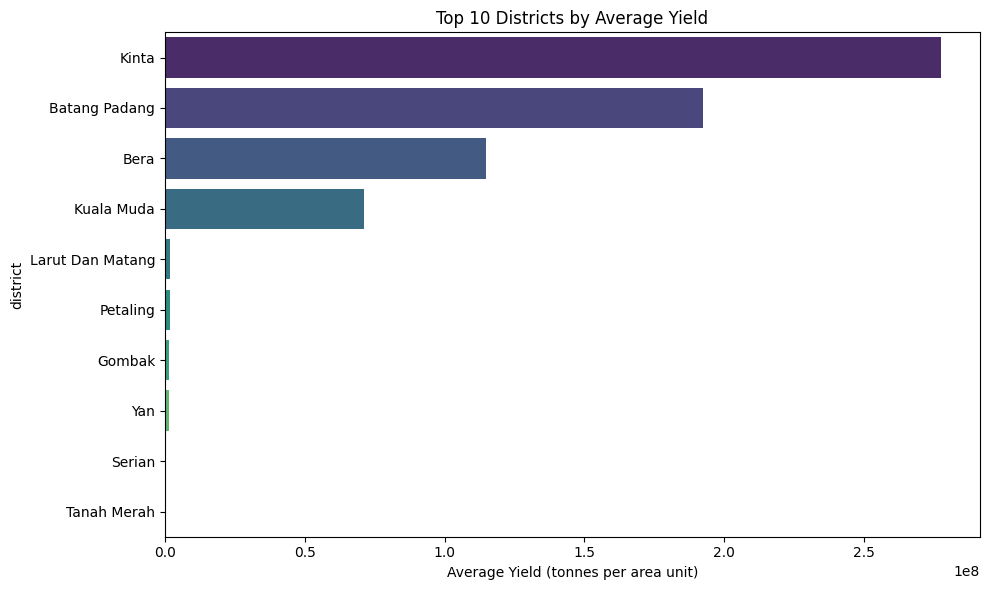

<ipython-input-20-965b8844ed7f>:45: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_crops.values, y=top_crops.index, palette='crest')


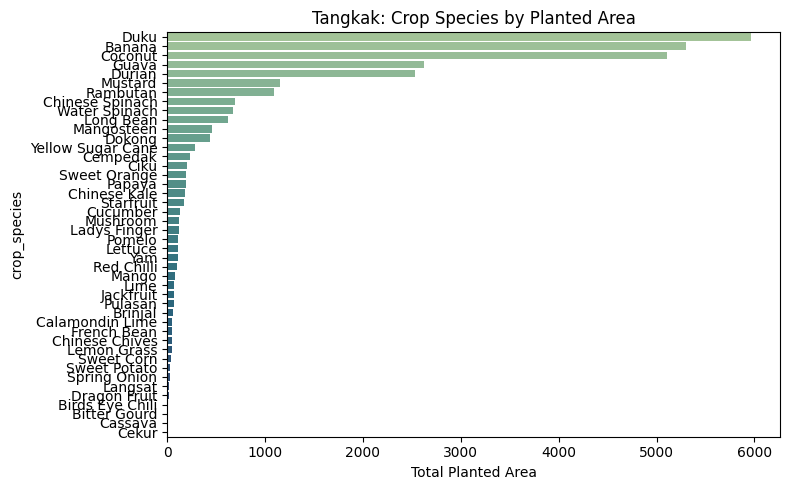

<ipython-input-20-965b8844ed7f>:45: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_crops.values, y=top_crops.index, palette='crest')


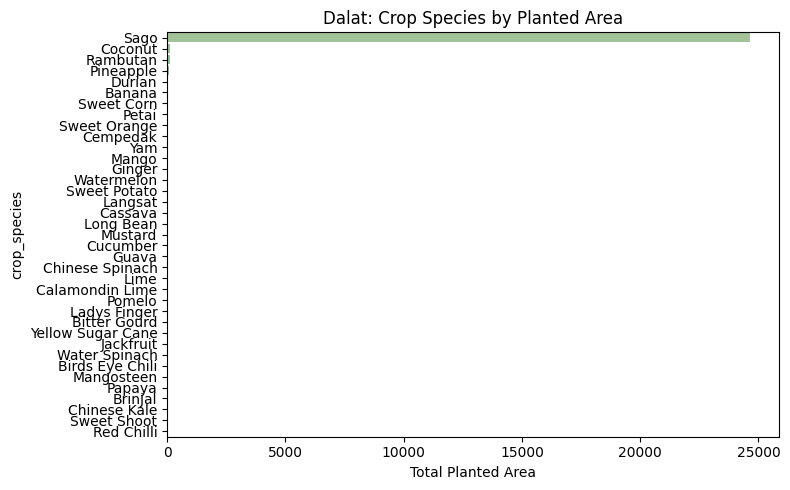

<ipython-input-20-965b8844ed7f>:45: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_crops.values, y=top_crops.index, palette='crest')


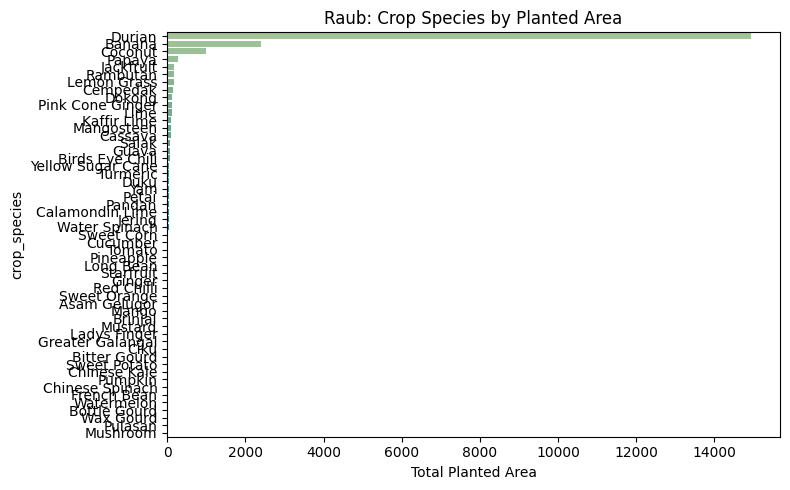

<ipython-input-20-965b8844ed7f>:54: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top10_crop_species_production.values, y=top10_crop_species_production.index, palette='magma')


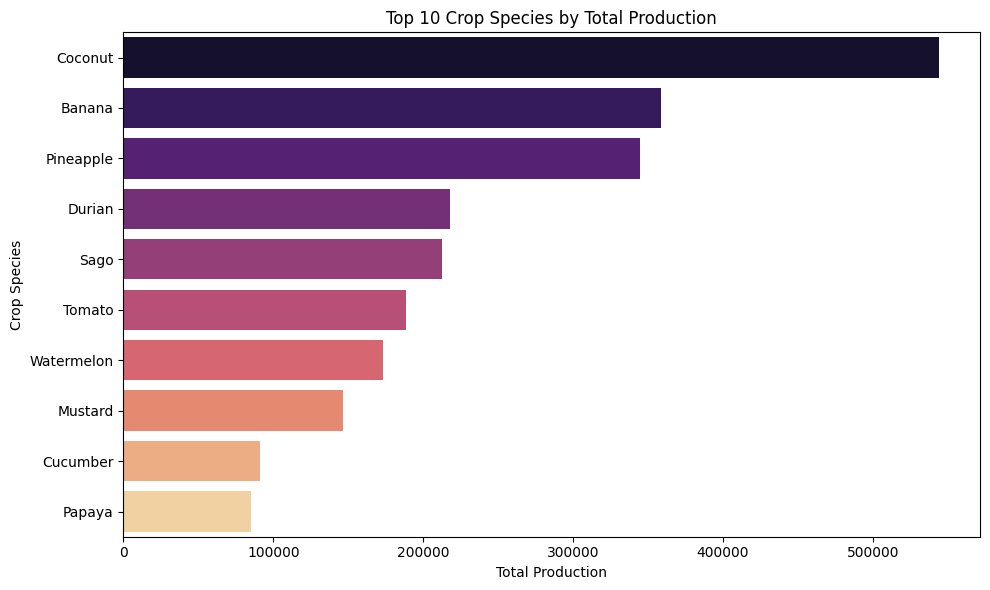

<ipython-input-20-965b8844ed7f>:65: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_species_area.values, y=top_species_area.index, palette='coolwarm')


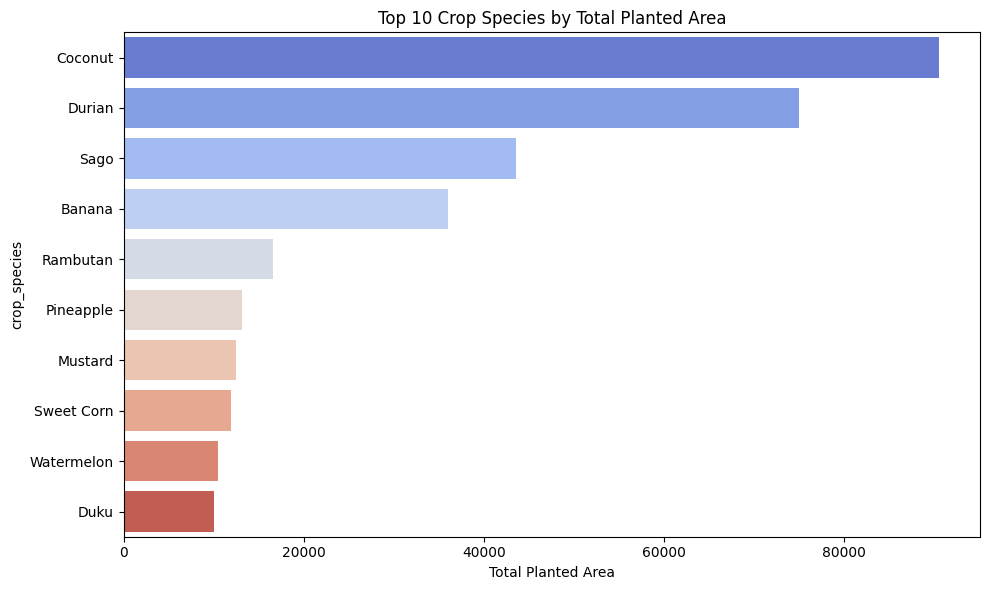

In [ ]:
# Top 10 Districts by Total Planted Area
top_district_area = merged_df[merged_df['district'] != 'Other'] \
    .groupby('district')['planted_area'].sum().sort_values(ascending=False).head(10)
plt.figure(figsize=(10, 6))
sns.barplot(x=top_district_area.values, y=top_district_area.index, palette='viridis')
plt.title('Top 10 Districts by Total Planted Area')
plt.xlabel('Total Planted Area')
plt.tight_layout()
plt.show()

# Top 10 Districts by Total Production
top_districts_prod = merged_df[merged_df['district'] != 'Other'] \
    .groupby('district')['production'].sum().sort_values(ascending=False).head(10)
plt.figure(figsize=(10, 6))
sns.barplot(x=top_districts_prod.values, y=top_districts_prod.index, palette='magma')
plt.title('Top 10 Districts by Total Production')
plt.xlabel('Total Production (tonnes)')
plt.ylabel('District')
plt.tight_layout()
plt.show()

# Top 10 Districts by Average Yield
import matplotlib.pyplot as plt

top_district_yield = merged_df[merged_df['district'] != 'Other'] \
    .groupby('district')['yield'].mean().sort_values(ascending=False).head(10)
plt.figure(figsize=(10, 6))
sns.barplot(x=top_district_yield.values, y=top_district_yield.index, palette='viridis')
plt.title('Top 10 Districts by Average Yield')
plt.xlabel('Average Yield (tonnes per area unit)')
plt.tight_layout()
plt.show()

# District-level Crop Species Breakdown
# 📍 Filter for specific districts
selected_districts = ['Tangkak', 'Dalat', 'Raub']
filtered_df = merged_df[merged_df['district'].isin(selected_districts)]

# 📊 Plot for each district
for district in selected_districts:
    district_df = filtered_df[filtered_df['district'] == district]
    top_crops = district_df.groupby('crop_species')['planted_area'].sum().sort_values(ascending=False)

    plt.figure(figsize=(8, 5))
    sns.barplot(x=top_crops.values, y=top_crops.index, palette='crest')
    plt.title(f'{district}: Crop Species by Planted Area')
    plt.xlabel('Total Planted Area')
    plt.tight_layout()
    plt.show()

# Top 10 Crop Species by Total Production
top10_crop_species_production = merged_df.groupby('crop_species')['production'].sum().sort_values(ascending=False).head(10)
plt.figure(figsize=(10, 6))
sns.barplot(x=top10_crop_species_production.values, y=top10_crop_species_production.index, palette='magma')
plt.title("Top 10 Crop Species by Total Production")
plt.xlabel("Total Production")
plt.ylabel("Crop Species")
plt.tight_layout()
plt.show()

# Top 10 Crop Species by Total Planted Area
top_species_area = merged_df[merged_df['crop_species'] != 'Other'] \
    .groupby('crop_species')['planted_area'].sum().sort_values(ascending=False).head(10)
plt.figure(figsize=(10, 6))
sns.barplot(x=top_species_area.values, y=top_species_area.index, palette='coolwarm')
plt.title('Top 10 Crop Species by Total Planted Area')
plt.xlabel('Total Planted Area')
plt.tight_layout()
plt.show()



---
**Predictive Analytics - Visualizations based on Models**


---




Scatterplot - Actual Prediction versus Predicted Production of All Models

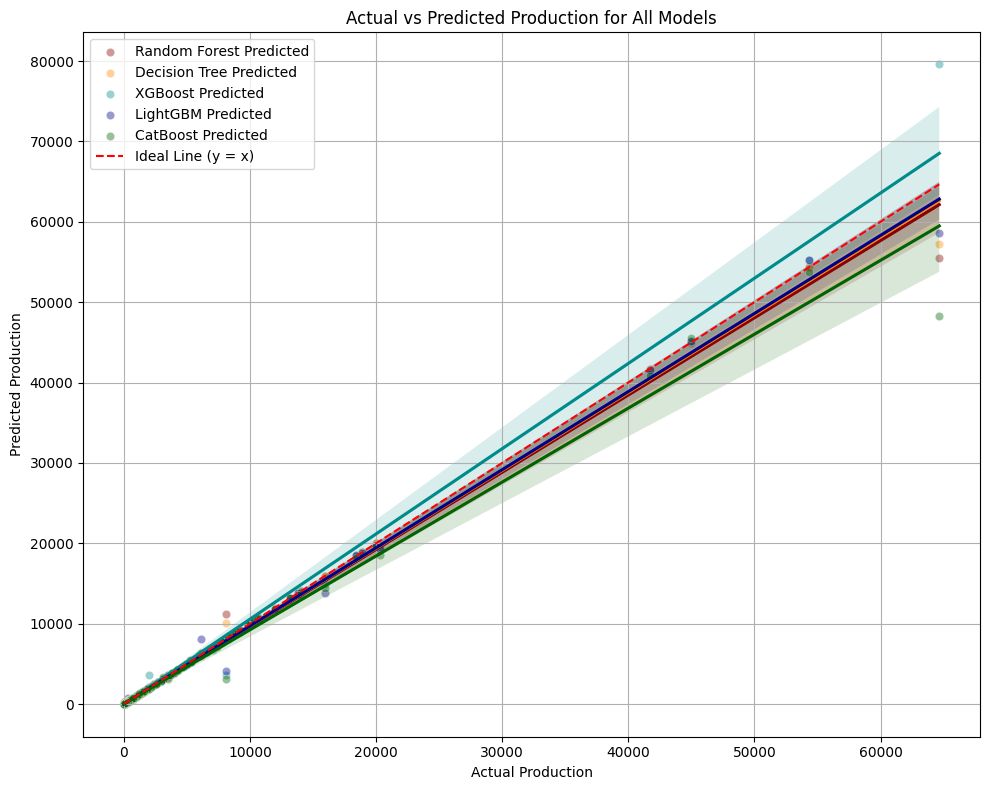

In [ ]:
plt.figure(figsize=(10, 8))

# Define colors for each model
colors = {
    'Random Forest': 'darkred',
    'Decision Tree': 'darkorange',
    'XGBoost': 'darkcyan',
    'LightGBM': 'darkblue',
    'CatBoost': 'darkgreen'
}

for model_name in all_results:
    true_vals = all_results[model_name]['true']
    pred_vals = all_results[model_name]['pred']
    color = colors[model_name]

    # Scatter points
    sns.scatterplot(x=true_vals, y=pred_vals, alpha=0.4, color=color, label=f'{model_name} Predicted')

    # Trend line with regplot (no scatter)
    sns.regplot(x=true_vals, y=pred_vals, scatter=False, color=color,
                line_kws={'label': f'{model_name} Trend'})

# Plot ideal y=x line
min_val = min(np.min(all_results[m]['true']) for m in all_results)
max_val = max(np.max(all_results[m]['true']) for m in all_results)
plt.plot([min_val, max_val], [min_val, max_val], 'r--', label='Ideal Line (y = x)')

plt.xlabel('Actual Production')
plt.ylabel('Predicted Production')
plt.title('Actual vs Predicted Production for All Models')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Comparison - Distribution of Residuals of All Models (Histogram)

<ipython-input-22-235d8580c964>:5: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(data['residuals'], label=model_name, shade=True)
<ipython-input-22-235d8580c964>:5: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(data['residuals'], label=model_name, shade=True)
<ipython-input-22-235d8580c964>:5: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(data['residuals'], label=model_name, shade=True)
<ipython-input-22-235d8580c964>:5: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(data['residuals'], label=model_na

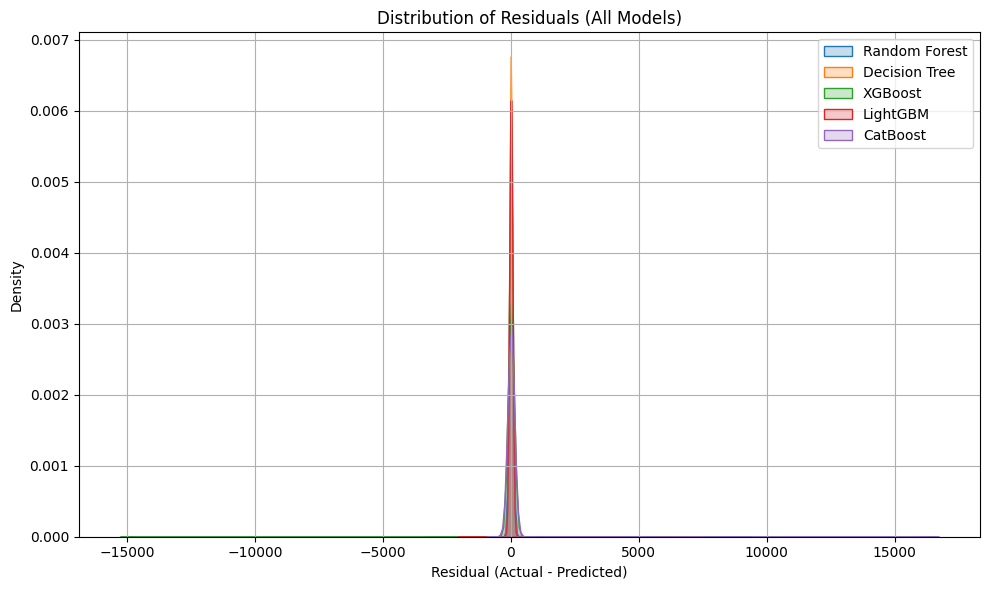

In [ ]:
plt.figure(figsize=(10, 6))

# Loop through each model's results in all_results
for model_name, data in all_results.items():
    sns.kdeplot(data['residuals'], label=model_name, shade=True)

plt.title("Distribution of Residuals (All Models)")
plt.xlabel("Residual (Actual - Predicted)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Comparison - LOESS Curve of Residuals vs Predicted Production of All Models

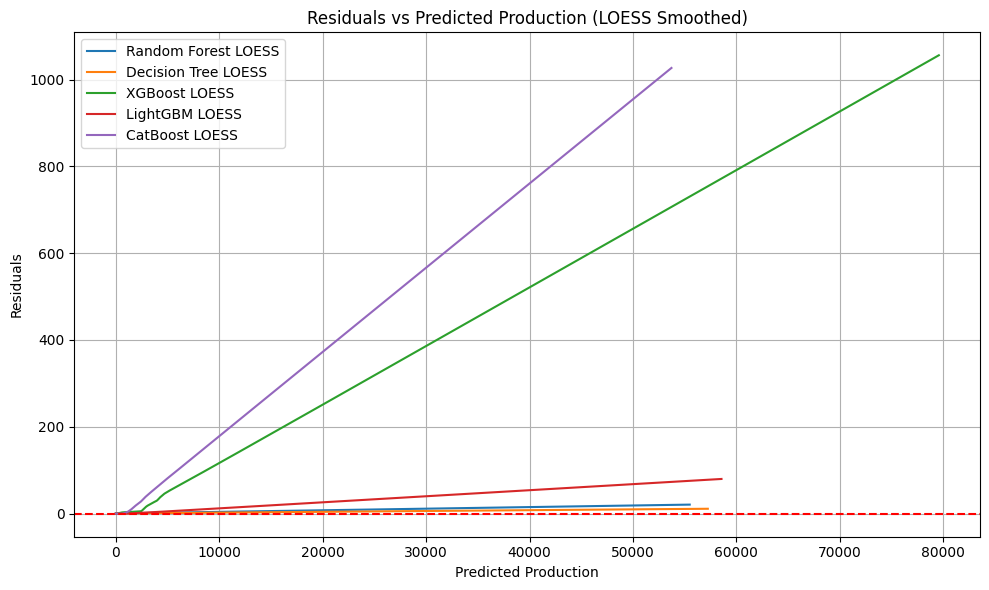

In [ ]:
# 📉 Residuals vs. Predicted (LOESS)
from statsmodels.nonparametric.smoothers_lowess import lowess

plt.figure(figsize=(10, 6))
for name, data in all_results.items():
    smoothed = lowess(data['residuals'], data['pred'])
    plt.plot(smoothed[:, 0], smoothed[:, 1], label=f'{name} LOESS')

plt.axhline(0, color='red', linestyle='--')
plt.title('Residuals vs Predicted Production (LOESS Smoothed)')
plt.xlabel("Predicted Production")
plt.ylabel("Residuals")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Residuals by District

<ipython-input-24-948a9a88e779>:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=avg_residuals.index, y=avg_residuals.values, palette='coolwarm')


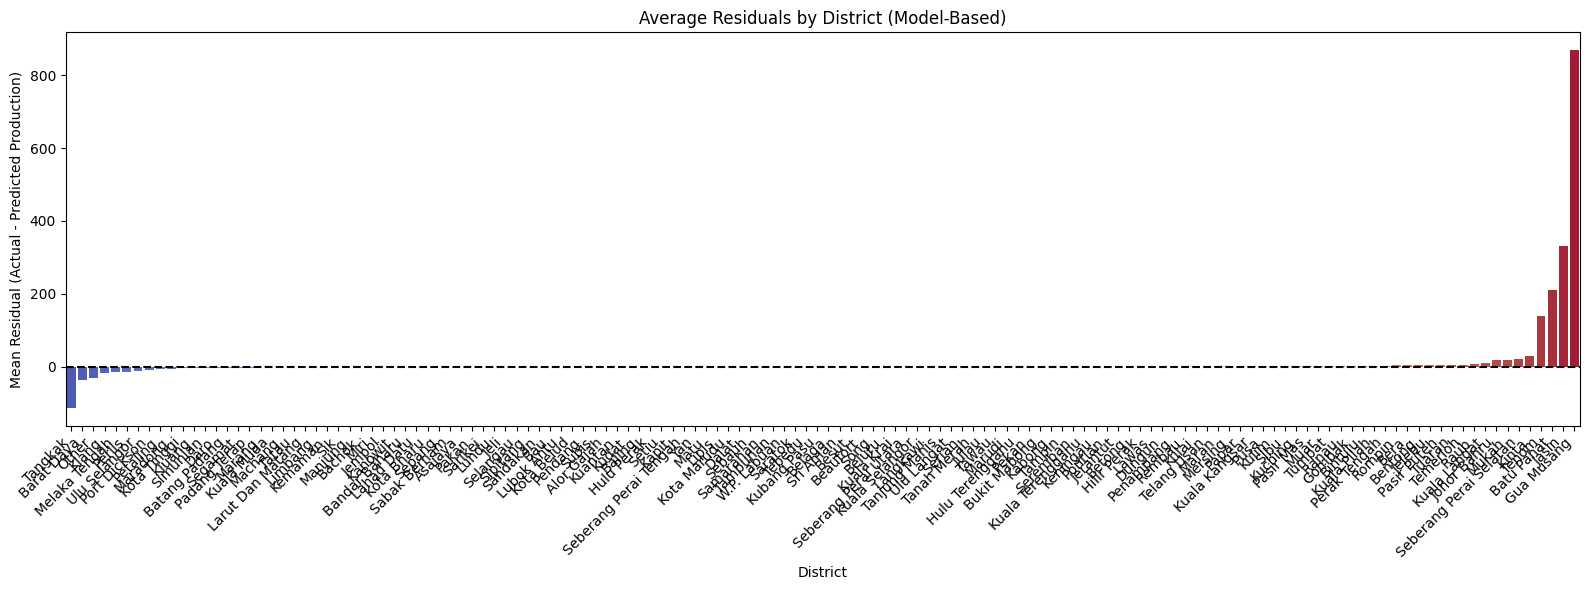

In [ ]:
# 🗺️ Residuals by District (Best Model, with larger figure and rotated labels)
residuals = all_results['LightGBM']['residuals']
X_test_meta = merged_df.loc[X_test.index, ['district']].copy()
X_test_meta['residual'] = residuals

# Group and sort
avg_residuals = X_test_meta.groupby('district')['residual'].mean().sort_values()

# Plot with larger width and rotated x-tick labels
plt.figure(figsize=(16, 6))  # Wider figure
sns.barplot(x=avg_residuals.index, y=avg_residuals.values, palette='coolwarm')
plt.xticks(rotation=45, ha='right')  # Rotate labels 45 degrees
plt.axhline(0, color='black', linestyle='--')
plt.title("Average Residuals by District (Model-Based)")
plt.ylabel("Mean Residual (Actual - Predicted Production)")
plt.xlabel("District")
plt.tight_layout()
plt.show()


Comparison - Top 5 Feature Importances of All Models

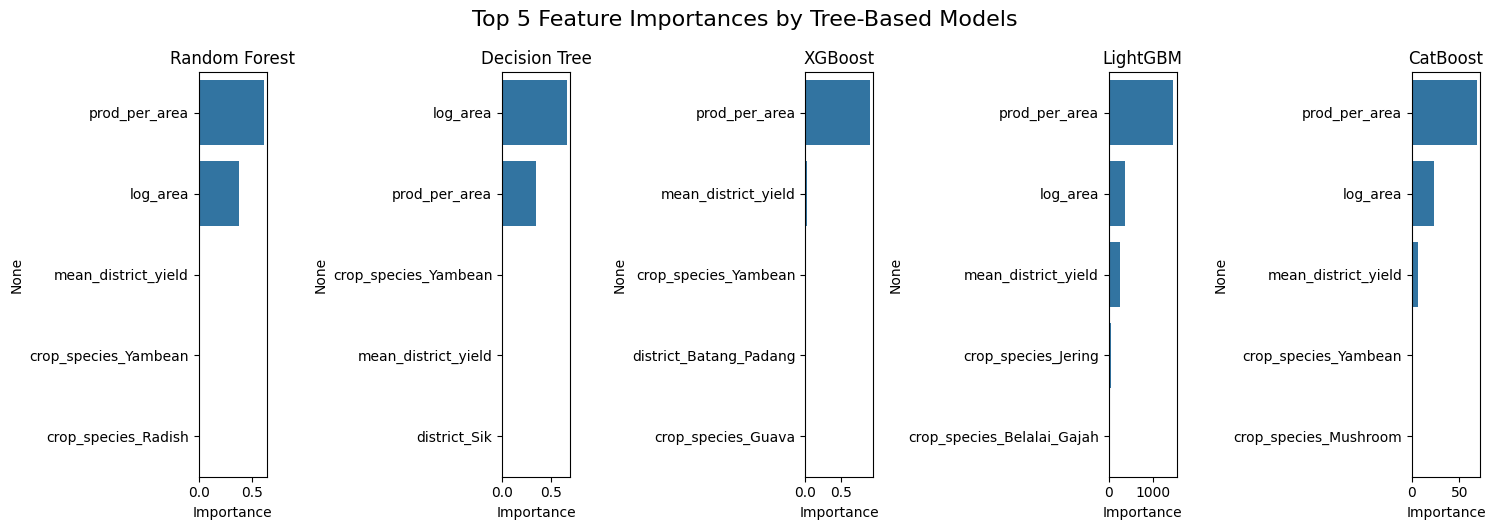

In [ ]:
models = {
    "Random Forest": best_rf,
    "Decision Tree": best_dt,
    "XGBoost": best_model,
    "LightGBM": best_lgb_model,
    "CatBoost": best_cat_model
}

# 🌟 Top 5 Feature Importances for Each Tree-Based Model
plt.figure(figsize=(15, 5))

for i, (name, model) in enumerate(models.items(), 1):
    if hasattr(model, 'feature_importances_'):
        importances = model.feature_importances_
        feat_df = pd.Series(importances, index=X.columns).sort_values(ascending=False).head(5)

        plt.subplot(1, 5, i)
        sns.barplot(x=feat_df.values, y=feat_df.index)
        plt.title(name)
        plt.xlabel('Importance')
        plt.tight_layout()

plt.suptitle("Top 5 Feature Importances by Tree-Based Models", fontsize=16, y=1.05)
plt.show()